Getting the data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error


data_path = Path("car_fuel_efficiency_2026.csv")
if not data_path.exists():
    data_path = Path("06-trees/06-homework/car_fuel_efficiency_2026.csv")
if not data_path.exists() and "__file__" in globals():
    data_path = Path(__file__).resolve().parent / "car_fuel_efficiency_2026.csv"

df = pd.read_csv(data_path)
df.head(20)

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
5,2007,USA,Hybrid,Front-wheel drive,2,2290,6,266.0,4260,18.8,31.2
6,1992,Asia,Gasoline,Front-wheel drive,2,2270,6,250.0,4310,21.7,26.8
7,2005,USA,Gasoline,Front-wheel drive,4,2370,6,279.0,4090,17.4,30.2
8,1997,Asia,Gasoline,Rear-wheel drive,3,2330,6,251.0,4230,19.5,30.9
9,2004,USA,Diesel,All-wheel drive,5,2330,6,280.0,4620,17.7,31.2


Data preparation

In [2]:
print("Data frame information:")
df.info()

print("Missing values:")
print(df.isnull().sum())

df = df.fillna(0)

print("Remaining missing values:")
print(df.isnull().sum())

Data frame information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   model_year           10000 non-null  int64  
 1   origin               10000 non-null  object 
 2   fuel_type            10000 non-null  object 
 3   drivetrain           10000 non-null  object 
 4   num_doors            10000 non-null  int64  
 5   engine_displacement  10000 non-null  int64  
 6   num_cylinders        10000 non-null  int64  
 7   horsepower           9123 non-null   float64
 8   vehicle_weight       10000 non-null  int64  
 9   acceleration         9736 non-null   float64
 10  fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(3), int64(5), object(3)
memory usage: 859.5+ KB
Missing values:
model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
eng

Splitting the data

In [3]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train["fuel_efficiency_mpg"].values
y_val = df_val["fuel_efficiency_mpg"].values

del df_train["fuel_efficiency_mpg"]
del df_val["fuel_efficiency_mpg"]

print("Training, validation and test sizes:")
print(len(df_train), len(df_val), len(df_test))

# Keep the test data for a final evaluation, outside parameter tuning.
train_dicts = df_train.to_dict(orient="records")
val_dicts = df_val.to_dict(orient="records")

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)
features = list(dv.get_feature_names_out())

print("Training and validation matrix shapes:")
print(X_train.shape, X_val.shape)

Training, validation and test sizes:
6000 2000 2000
Training and validation matrix shapes:
(6000, 16) (2000, 16)


Q1. Decision tree

In [4]:
dt = DecisionTreeRegressor(max_depth=1, random_state=1)
dt.fit(X_train, y_train)

print(export_text(dt, feature_names=features))

split_feature = features[dt.tree_.feature[0]]
original_feature = split_feature.split("=", 1)[0]

print("Splitting feature:")
print(split_feature)
print("Original column:")
print(original_feature)

# The first split is model_year <= 1997.5.
# Answer: model_year

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]

Splitting feature:
model_year
Original column:
model_year


Q2. Random forest

In [5]:
rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_val)
validation_rmse = root_mean_squared_error(y_val, y_pred)

print("Validation RMSE:")
print(validation_rmse)
print("Rounded RMSE:")
print(round(validation_rmse, 3))

# RMSE is about 1.837054 before rounding.
# Answer: 1.837

Validation RMSE:
1.837054054730018
Rounded RMSE:
1.837


Q3. Number of estimators

Number of estimators and validation RMSE:
   n_estimators   rmse
0            10  1.837
1            50  1.772
2           100  1.768
3           150  1.769
Best number of estimators:
100


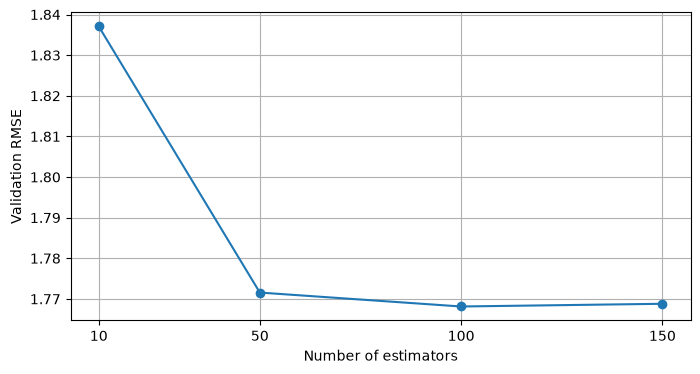

In [6]:
n_estimators_values = [10, 50, 100, 150]
scores = []

for n in n_estimators_values:
    rf = RandomForestRegressor(n_estimators=n, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)

    y_pred = rf.predict(X_val)
    rmse = root_mean_squared_error(y_val, y_pred)
    scores.append((n, rmse))

df_scores = pd.DataFrame(scores, columns=["n_estimators", "rmse"])
print("Number of estimators and validation RMSE:")
print(df_scores.round(3))

# Compare RMSE rounded to 3 decimal places, as in the question.
rounded_scores = df_scores["rmse"].round(3)
best_n = int(df_scores.loc[rounded_scores.idxmin(), "n_estimators"])
print("Best number of estimators:")
print(best_n)

plt.figure(figsize=(8, 4))
plt.plot(df_scores["n_estimators"], df_scores["rmse"], marker="o")
plt.xticks(n_estimators_values)
plt.xlabel("Number of estimators")
plt.ylabel("Validation RMSE")
plt.grid()
plt.show()

# The lowest rounded RMSE is 1.768 with 100 trees.
# Answer: 100

Q4. Best max depth

Validation RMSE for each combination:
n_estimators    10     50     100    150
max_depth                               
10            1.784  1.749  1.745  1.745
15            1.830  1.771  1.768  1.767
20            1.841  1.773  1.769  1.770
25            1.837  1.772  1.768  1.768
Mean validation RMSE for each max depth:
max_depth
10    1.755405
15    1.783953
20    1.788242
25    1.786317
Name: rmse, dtype: float64
Best max depth:
10


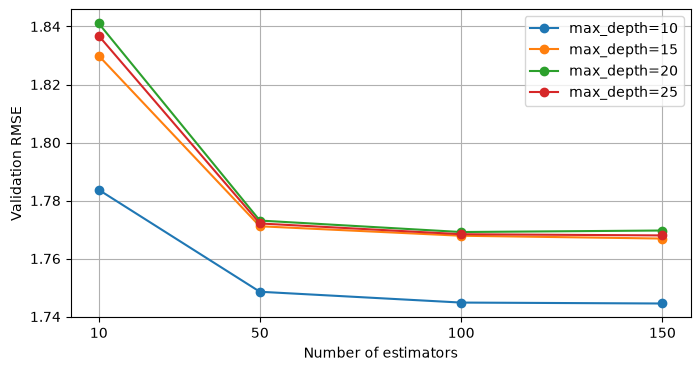

In [7]:
depths = [10, 15, 20, 25]
scores = []

for depth in depths:
    for n in n_estimators_values:
        rf = RandomForestRegressor(
            n_estimators=n, max_depth=depth, random_state=1, n_jobs=-1
        )
        rf.fit(X_train, y_train)

        y_pred = rf.predict(X_val)
        rmse = root_mean_squared_error(y_val, y_pred)
        scores.append((depth, n, rmse))

df_depth_scores = pd.DataFrame(
    scores, columns=["max_depth", "n_estimators", "rmse"]
)

print("Validation RMSE for each combination:")
print(df_depth_scores.pivot(
    index="max_depth", columns="n_estimators", values="rmse"
).round(3))

# Calculate the mean from the original scores before rounding.
mean_rmse = df_depth_scores.groupby("max_depth")["rmse"].mean()
print("Mean validation RMSE for each max depth:")
print(mean_rmse)

best_depth = int(mean_rmse.idxmin())
print("Best max depth:")
print(best_depth)

plt.figure(figsize=(8, 4))
for depth in depths:
    df_subset = df_depth_scores[df_depth_scores["max_depth"] == depth]
    plt.plot(
        df_subset["n_estimators"], df_subset["rmse"],
        marker="o", label=f"max_depth={depth}"
    )

plt.xticks(n_estimators_values)
plt.xlabel("Number of estimators")
plt.ylabel("Validation RMSE")
plt.legend()
plt.grid()
plt.show()

# Max depth 10 gives the lowest mean RMSE: about 1.755405.
# Answer: 10

Q5. Feature importance

Feature importance:
model_year                      0.296001
vehicle_weight                  0.203879
fuel_type=Gasoline              0.160712
horsepower                      0.078017
engine_displacement             0.061005
acceleration                    0.055201
origin=USA                      0.042144
drivetrain=Front-wheel drive    0.020145
num_doors                       0.019415
fuel_type=Diesel                0.017038
fuel_type=Hybrid                0.015800
drivetrain=All-wheel drive      0.007682
num_cylinders                   0.007284
origin=Asia                     0.006391
drivetrain=Rear-wheel drive     0.005781
origin=Europe                   0.003505
dtype: float64
Feature importance for the four options:
vehicle_weight         0.203879
horsepower             0.078017
engine_displacement    0.061005
acceleration           0.055201
dtype: float64
Most important feature among the four options:
vehicle_weight


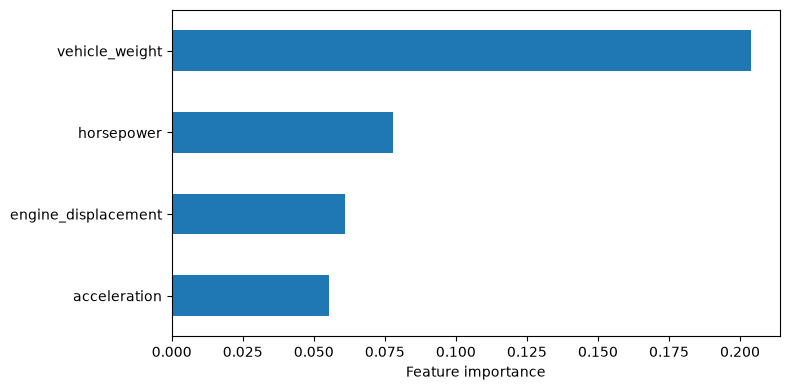

In [8]:
rf = RandomForestRegressor(
    n_estimators=10, max_depth=20, random_state=1, n_jobs=-1
)
rf.fit(X_train, y_train)

feature_importance = pd.Series(
    rf.feature_importances_, index=features
).sort_values(ascending=False)

print("Feature importance:")
print(feature_importance)

candidates = ["vehicle_weight", "horsepower", "acceleration", "engine_displacement"]
candidate_importance = feature_importance.loc[candidates].sort_values(ascending=False)
print("Feature importance for the four options:")
print(candidate_importance)
print("Most important feature among the four options:")
print(candidate_importance.idxmax())

plt.figure(figsize=(8, 4))
candidate_importance.sort_values().plot.barh()
plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()

# Vehicle weight has importance about 0.204, the highest among the four options.
# Model year has the highest importance overall.
# Answer: vehicle_weight

Q6. XGBoost eta

Eta and validation RMSE after 100 rounds:
   eta      rmse
0  0.3  1.826458
1  0.1  1.724810
Best eta:
0.1


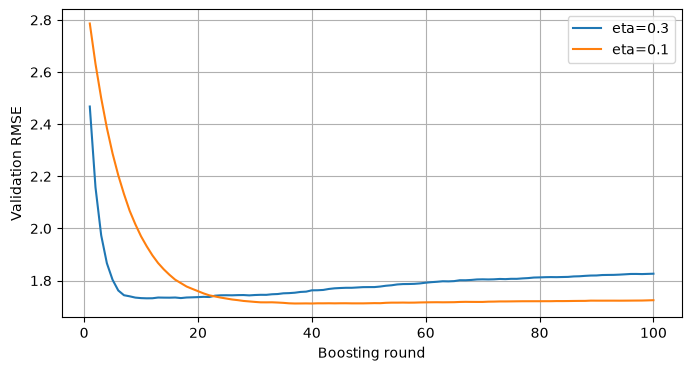

In [9]:
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)
watchlist = [(dtrain, "train"), (dval, "val")]

xgb_params = {
    "eta": 0.3,
    "max_depth": 6,
    "min_child_weight": 1,
    "objective": "reg:squarederror",
    "nthread": 8,
    "seed": 1,
    "verbosity": 1,
}

scores = []
learning_curves = {}

for eta in [0.3, 0.1]:
    xgb_params["eta"] = eta
    evals_result = {}

    model = xgb.train(
        xgb_params,
        dtrain,
        num_boost_round=100,
        evals=watchlist,
        evals_result=evals_result,
        verbose_eval=False,
    )

    y_pred = model.predict(dval)
    rmse = root_mean_squared_error(y_val, y_pred)
    scores.append((eta, rmse))
    learning_curves[eta] = evals_result["val"]["rmse"]

df_eta_scores = pd.DataFrame(scores, columns=["eta", "rmse"])
print("Eta and validation RMSE after 100 rounds:")
print(df_eta_scores)

best_eta = df_eta_scores.loc[df_eta_scores["rmse"].idxmin(), "eta"]
print("Best eta:")
print(best_eta)

plt.figure(figsize=(8, 4))
for eta, curve in learning_curves.items():
    plt.plot(np.arange(1, 101), curve, label=f"eta={eta}")

plt.xlabel("Boosting round")
plt.ylabel("Validation RMSE")
plt.legend()
plt.grid()
plt.show()

# After 100 rounds, RMSE is about 1.826458 for eta=0.3 and 1.724810 for eta=0.1.
# Answer: 0.1